<a href="https://colab.research.google.com/github/Maurofome/Portafolio_Actividades_MineriaDatos_-MauricioAliaga/blob/main/Lab2_10_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Paso 1: Hipótesis

In [17]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

ruta = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")
print(os.listdir(ruta))
df = pd.read_csv(os.path.join(ruta, "Mall_Customers.csv"))

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.
['Mall_Customers.csv']


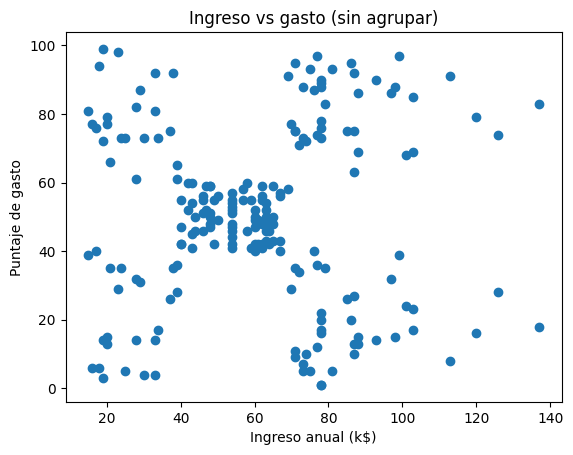

In [18]:
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"])
plt.xlabel("Ingreso anual (k$)")
plt.ylabel("Puntaje de gasto")
plt.title("Ingreso vs gasto (sin agrupar)")
plt.show()

Veo 5 grupos: uno al centro y cuatro en las esquinas. Lo deduzco porque los puntos forman nubes separadas por espacios vacíos.

Paso 2: Explorar

In [19]:
print(df.shape)
df.info()
print(df.isna().sum())
print(df["Gender"].value_counts())
df.describe()

(200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Gender
Female    112
Male       88
Name: count, dtype: int64


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


Hay 200 clientes y 5 columnas, sin valores nulos. La unidad de análisis es el cliente. CustomerID no se usa porque es solo un número de identificación y no representa ninguna distancia real. Gender tampoco entra al modelo: si se codifica como 0/1, genera una distancia artificial entre hombres y mujeres que puede separar los grupos solo por género. Lo usaré únicamente para describir los grupos.

Paso 3: Preparar y estandarizar

In [20]:
from sklearn.preprocessing import StandardScaler

X = df[["Annual Income (k$)", "Spending Score (1-100)"]]
print(X.min())
print(X.max())

scaler = StandardScaler()
X_std = scaler.fit_transform(X)

Annual Income (k$)        15
Spending Score (1-100)     1
dtype: int64
Annual Income (k$)        137
Spending Score (1-100)     99
dtype: int64


El ingreso va de 15 a 137 y el gasto de 1 a 99. Decido estandarizar para que ambas variables pesen lo mismo en la distancia. Guardo las dos versiones (X y X_std) para compararlas en el paso 5.

Paso 4: Probar distintos k

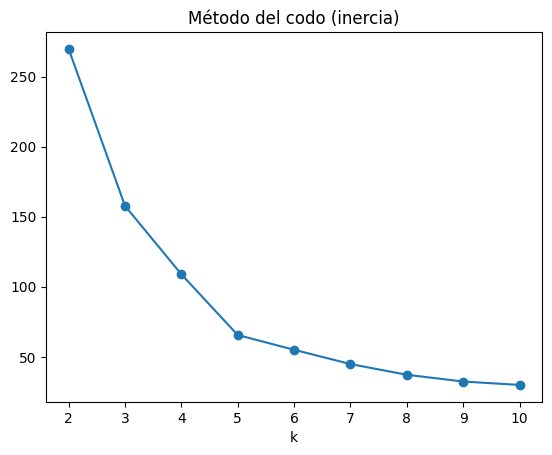

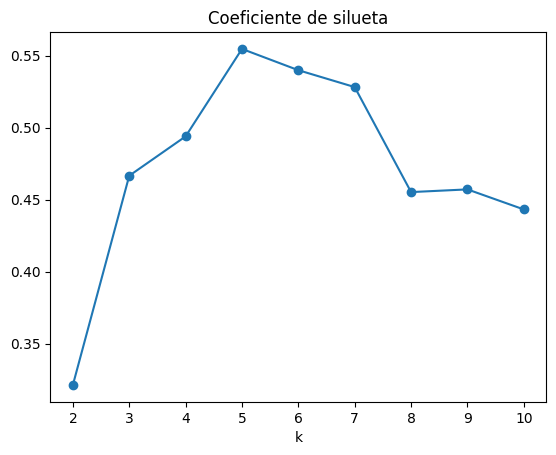

In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inercias = []
siluetas = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_std)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_std, km.labels_))

plt.plot(range(2, 11), inercias, "o-")
plt.title("Método del codo (inercia)")
plt.xlabel("k")
plt.show()

plt.plot(range(2, 11), siluetas, "o-")
plt.title("Coeficiente de silueta")
plt.xlabel("k")
plt.show()

La inercia siempre baja al aumentar k, porque con más grupos cada punto queda más cerca de algún centro. Si usara solo esa curva, siempre elegiría más grupos. Por eso la complemento con la silueta. El codo aparece en k = 5 y la silueta también es máxima en k = 5.

Paso 5: Más evidencia

In [22]:
from sklearn.metrics import adjusted_rand_score

base = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X_std).labels_

# Estabilidad: misma k con otra semilla
otra = KMeans(n_clusters=5, n_init=10, random_state=7).fit(X_std).labels_
print("ARI con otra semilla:", round(adjusted_rand_score(base, otra), 3))

# Mini-experimento: sin estandarizar
sin_std = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X).labels_
print("ARI con vs sin estandarizar:", round(adjusted_rand_score(base, sin_std), 3))
print(pd.crosstab(base, sin_std))

ARI con otra semilla: 1.0
ARI con vs sin estandarizar: 1.0
col_0   0   1   2   3   4
row_0                    
0      81   0   0   0   0
1       0  39   0   0   0
2       0   0  22   0   0
3       0   0   0  35   0
4       0   0   0   0  23


Elijo k = 5 por tres evidencias: (1) el codo y la silueta coinciden en 5; (2) los grupos se repiten con otra semilla, con un ARI cercano a 1; (3) cada grupo se puede describir y recibir una acción distinta. Con y sin estandarizar el resultado es casi igual, porque ambas variables ya tenían rangos parecidos.

Paso 6: Interpretar

cluster
0    81
1    39
3    35
4    23
2    22
Name: count, dtype: int64
          Age  Annual Income (k$)  Spending Score (1-100)
cluster                                                  
0        42.7                55.3                    49.5
1        32.7                86.5                    82.1
2        25.3                25.7                    79.4
3        41.1                88.2                    17.1
4        45.2                26.3                    20.9


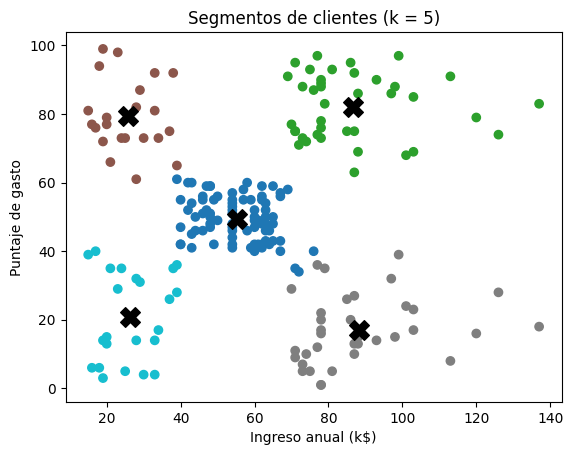

In [23]:
km_final = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X_std)
df["cluster"] = km_final.labels_

print(df["cluster"].value_counts())
print(df.groupby("cluster")[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].mean().round(1))

centros = scaler.inverse_transform(km_final.cluster_centers_)
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"], c=df["cluster"], cmap="tab10")
plt.scatter(centros[:, 0], centros[:, 1], c="black", marker="X", s=200)
plt.xlabel("Ingreso anual (k$)")
plt.ylabel("Puntaje de gasto")
plt.title("Segmentos de clientes (k = 5)")
plt.show()

Las nubes del gráfico inicial coinciden con los grupos de K-means. Los clientes que más gastan suelen ser más jóvenes, aunque la edad no entró al modelo. Estos grupos solo valen para ingreso y gasto estandarizados, y no dicen nada sobre la personalidad de los clientes.

Ejercicio 2 · Clustering jerárquico: ¿Con qué países se parece Chile?

Paso 1: Hipótesis y muestra

In [24]:
ruta2 = kagglehub.dataset_download("rohan0301/unsupervised-learning-on-country-data")
print(os.listdir(ruta2))
paises = pd.read_csv(os.path.join(ruta2, "Country-data.csv"))

lista = ["Chile", "Argentina", "Brazil", "Bolivia", "Colombia", "Ecuador", "Paraguay",
         "Peru", "Uruguay", "Venezuela", "Mexico", "Guatemala", "Panama", "Costa Rica",
         "El Salvador", "Dominican Republic", "Jamaica", "Haiti",
         "United States", "Canada", "Spain", "Portugal", "Germany", "France",
         "Poland", "Japan", "Australia", "China", "India", "Nigeria"]

print("No encontrados:", [p for p in lista if p not in paises["country"].values])
sub = paises[paises["country"].isin(lista)].set_index("country")
print(len(sub), "países")

Using Colab cache for faster access to the 'unsupervised-learning-on-country-data' dataset.
['Country-data.csv', 'data-dictionary.csv']
No encontrados: ['Mexico']
29 países


Elegí los países de Latinoamérica más algunos de referencia de otras regiones , unos 30 en total pero Mexico no esta.
Hipótesis: creo que Chile se agrupará con Uruguay, Argentina, Costa Rica y Panamá, por tener ingresos e indicadores de salud parecidos.

Paso 2: Explorar

country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64
       child_mort  exports  health  imports    income  inflation  life_expec  \
count       167.0    167.0   167.0    167.0     167.0      167.0       167.0   
mean         38.3     41.1     6.8     46.9   17144.7        7.8        70.6   
std          40.3     27.4     2.7     24.2   19278.1       10.6         8.9   
min           2.6      0.1     1.8      0.1     609.0       -4.2        32.1   
25%           8.2     23.8     4.9     30.2    3355.0        1.8        65.3   
50%          19.3     35.0     6.3     43.3    9960.0        5.4        73.1   
75%          62.1     51.4     8.6     58.8   22800.0       10.8        76.8   
max         208.0    200.0    17.9    174.0  125000.0      104.0        82.8   

       total_fer      gdpp  
count      167.0     167.0  
mean         2.9   12964.2  
std          1.5   

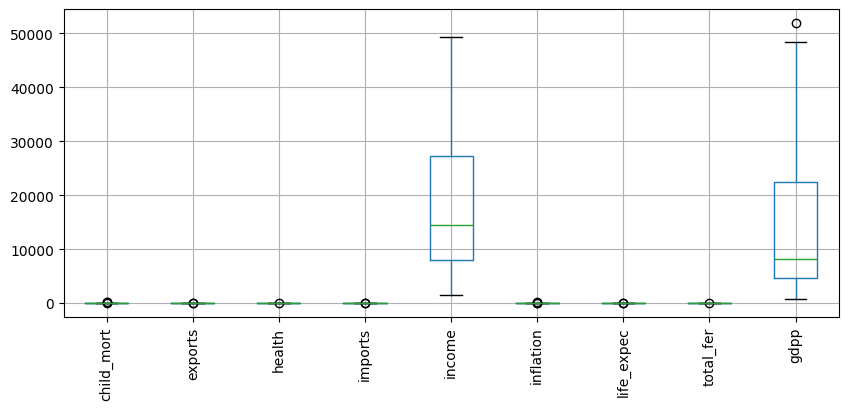

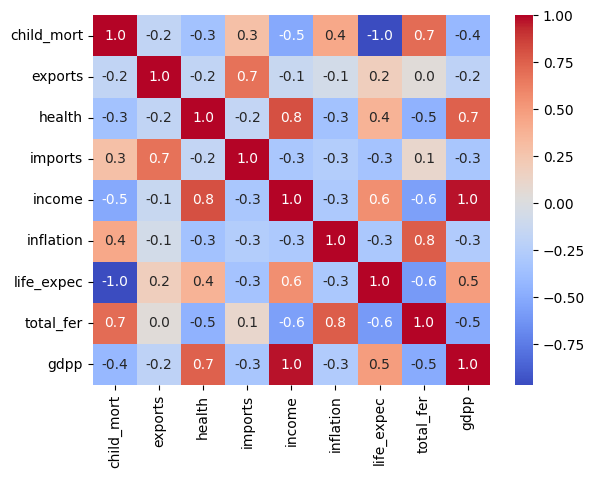

In [25]:
import seaborn as sns

print(paises.isna().sum())
print(paises.describe().round(1))

sub.boxplot(rot=90, figsize=(10, 4))
plt.show()

sns.heatmap(sub.corr(), annot=True, fmt=".1f", cmap="coolwarm")
plt.show()

No hay valores nulos. income y gdpp están en decenas de miles, mientras que las demás variables están bajo 100. Sin preparar los datos, esas dos variables dominarían la distancia euclidiana. Además, child_mort y total_fer están muy correlacionadas, igual que income y gdpp.

Paso 3: Preparar

In [26]:
X2 = sub.values
X2_std = StandardScaler().fit_transform(sub)

Sin estandarizar, el dendrograma agrupará a los países casi solo por ingreso. Al estandarizar, todas las variables pesarán lo mismo y los grupos cambiarán.

Paso 4: Dendrogramas

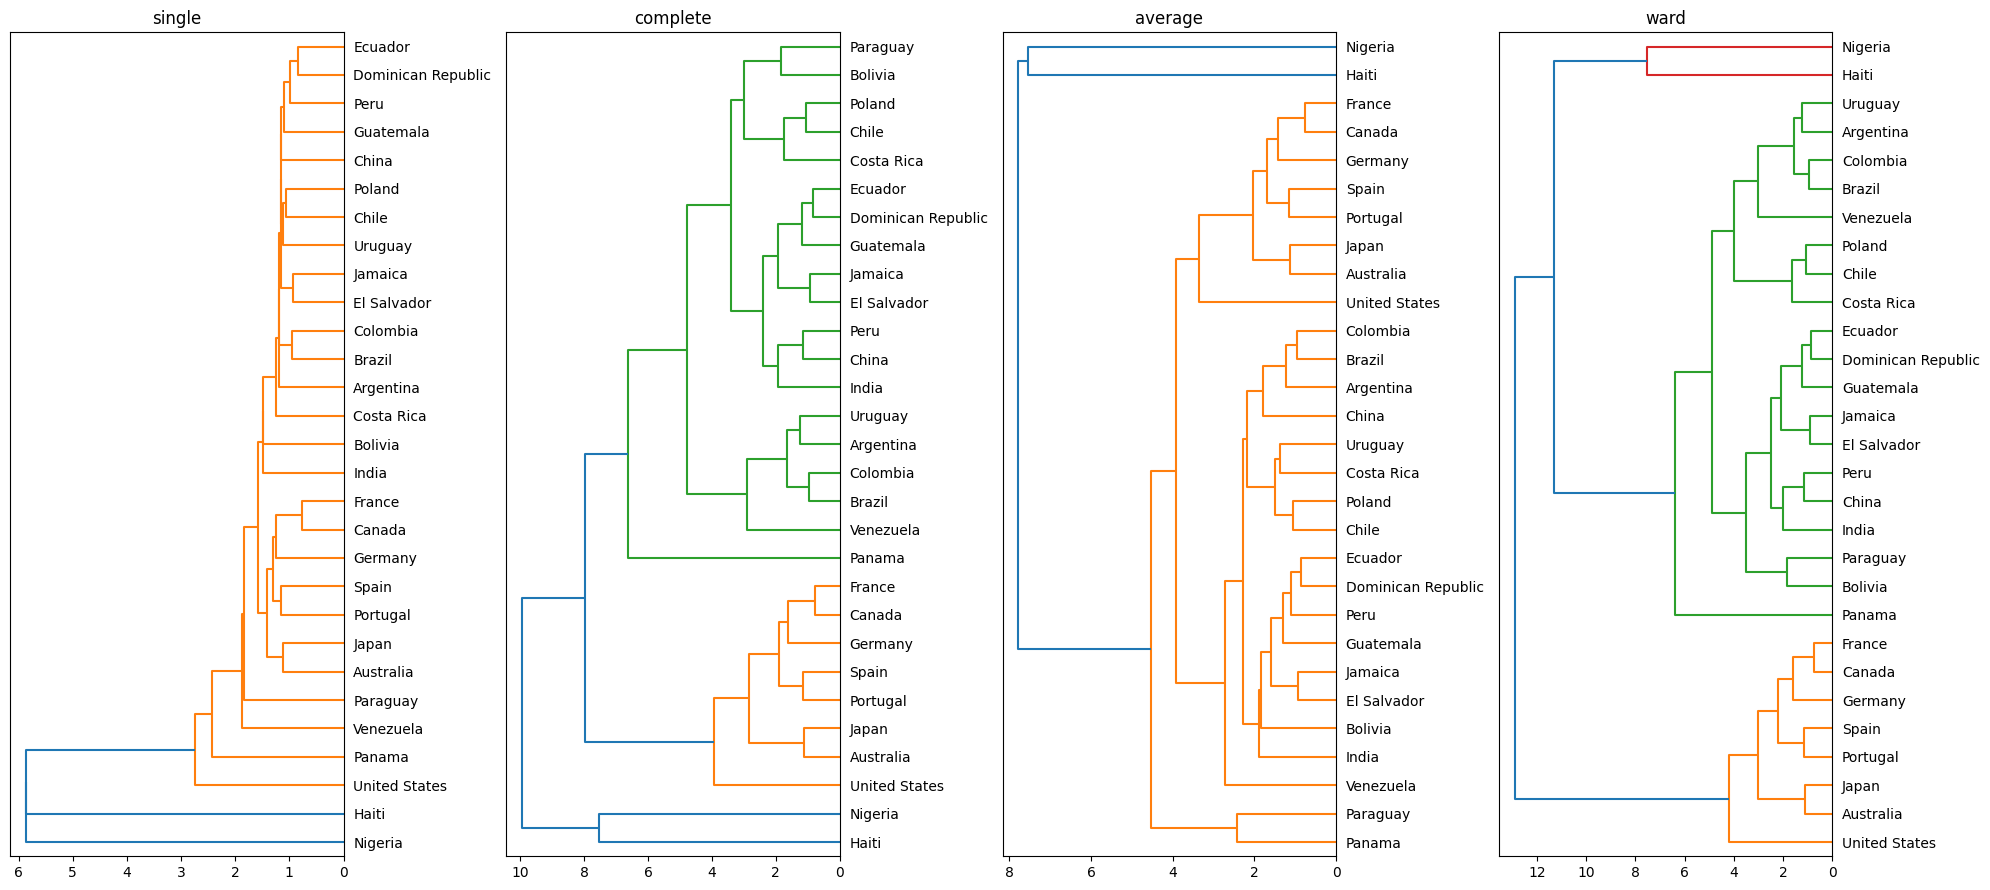

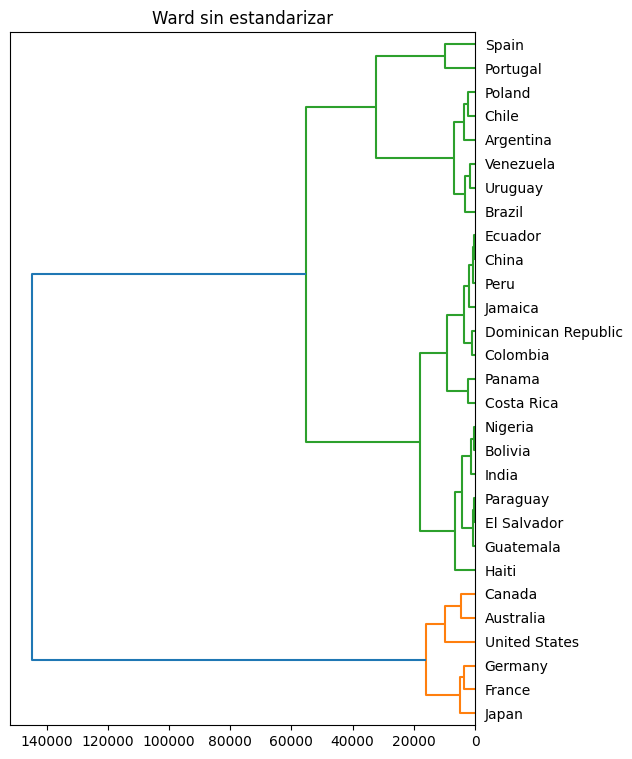

In [27]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

fig, ax = plt.subplots(1, 4, figsize=(20, 9))
for i, metodo in enumerate(["single", "complete", "average", "ward"]):
    Z = linkage(X2_std, method=metodo)
    dendrogram(Z, labels=sub.index.tolist(), orientation="left", ax=ax[i])
    ax[i].set_title(metodo)
plt.tight_layout()
plt.show()

# Ward sin estandarizar
plt.figure(figsize=(6, 9))
dendrogram(linkage(X2, method="ward"), labels=sub.index.tolist(), orientation="left")
plt.title("Ward sin estandarizar")
plt.show()

Single forma una “escalera”: une los países de a uno, sin grupos claros. Complete y ward forman grupos más compactos y equilibrados, y average queda en un punto intermedio. Prefiero ward.
Sin estandarizar, los grupos dependen casi solo de income y gdpp, así que mi predicción se cumplió. Ward solo admite distancia euclidiana.

Paso 5: Cortar

2 grupos → silueta: 0.331
3 grupos → silueta: 0.38
4 grupos → silueta: 0.382
5 grupos → silueta: 0.368
Alturas de las últimas fusiones: [ 4.88  6.41  7.53 11.31 12.91]


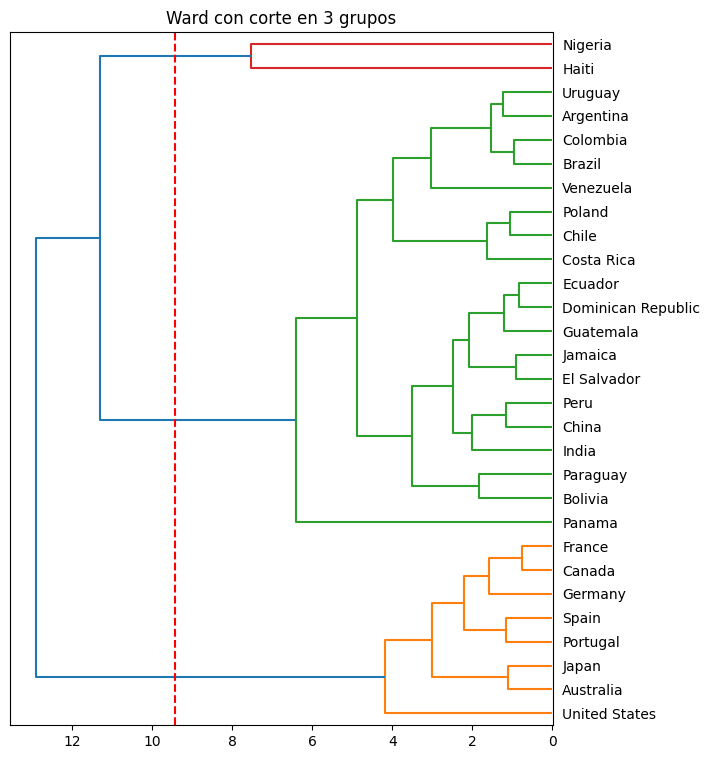

In [28]:
Z = linkage(X2_std, method="ward")

for k in [2, 3, 4, 5]:
    etiq = fcluster(Z, k, criterion="maxclust")
    print(k, "grupos → silueta:", round(silhouette_score(X2_std, etiq), 3))

print("Alturas de las últimas fusiones:", Z[-5:, 2].round(2))

k = 3   # cámbialo si la evidencia indica otro
corte = (Z[-k, 2] + Z[-k + 1, 2]) / 2
plt.figure(figsize=(7, 9))
dendrogram(Z, labels=sub.index.tolist(), orientation="left", color_threshold=corte)
plt.axvline(corte, color="red", linestyle="--")
plt.title(f"Ward con corte en {k} grupos")
plt.show()

Elijo cortar en 3 grupos: hay un salto grande de altura antes de las últimas fusiones, la silueta es buena y los grupos se pueden describir (desarrollados, ingreso medio y bajo desarrollo). La altura mide qué tan distintos son los grupos que se unen, no qué tan buenos son.

Paso 6: Interpretar y comparar con K-means

In [29]:
sub["grupo"] = fcluster(Z, k, criterion="maxclust")

for g, d in sub.groupby("grupo"):
    print(f"Grupo {g}: {list(d.index)}")

print(sub.groupby("grupo").mean().round(1))
print("Chile está en el grupo", sub.loc["Chile", "grupo"])

km2 = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X2_std)
print(pd.crosstab(sub["grupo"], km2.labels_, rownames=["Jerárquico"], colnames=["K-means"]))
print("ARI:", round(adjusted_rand_score(sub["grupo"], km2.labels_), 3))

Grupo 1: ['Australia', 'Canada', 'France', 'Germany', 'Japan', 'Portugal', 'Spain', 'United States']
Grupo 2: ['Argentina', 'Bolivia', 'Brazil', 'Chile', 'China', 'Colombia', 'Costa Rica', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Guatemala', 'India', 'Jamaica', 'Panama', 'Paraguay', 'Peru', 'Poland', 'Uruguay', 'Venezuela']
Grupo 3: ['Haiti', 'Nigeria']
       child_mort  exports  health  imports   income  inflation  life_expec  \
grupo                                                                         
1             4.6     25.1    11.4     26.3  38037.5        0.7        81.0   
2            22.3     31.0     6.8     33.3  11913.7        9.0        75.1   
3           169.0     20.3     6.0     41.0   3325.0       54.7        46.3   

       total_fer     gdpp  
grupo                      
1            1.6  40975.0  
2            2.3   6930.5  
3            4.6   1496.0  
Chile está en el grupo 2
K-means     0  1   2
Jerárquico          
1           8  0   0
2           

In [30]:
for k_test in [3, 4, 5, 6, 8]:
    etiq = fcluster(Z, k_test, criterion="maxclust")
    grupo_chile = etiq[sub.index.get_loc("Chile")]
    vecinos = sub.index[etiq == grupo_chile].tolist()
    print(f"{k_test} grupos → Chile con: {vecinos}")

3 grupos → Chile con: ['Argentina', 'Bolivia', 'Brazil', 'Chile', 'China', 'Colombia', 'Costa Rica', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Guatemala', 'India', 'Jamaica', 'Panama', 'Paraguay', 'Peru', 'Poland', 'Uruguay', 'Venezuela']
4 grupos → Chile con: ['Argentina', 'Bolivia', 'Brazil', 'Chile', 'China', 'Colombia', 'Costa Rica', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Guatemala', 'India', 'Jamaica', 'Panama', 'Paraguay', 'Peru', 'Poland', 'Uruguay', 'Venezuela']
5 grupos → Chile con: ['Argentina', 'Bolivia', 'Brazil', 'Chile', 'China', 'Colombia', 'Costa Rica', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Guatemala', 'India', 'Jamaica', 'Paraguay', 'Peru', 'Poland', 'Uruguay', 'Venezuela']
6 grupos → Chile con: ['Argentina', 'Brazil', 'Chile', 'Colombia', 'Costa Rica', 'Poland', 'Uruguay', 'Venezuela']
8 grupos → Chile con: ['Chile', 'Costa Rica', 'Poland']


¿Con quién se agrupa Chile? Con 3 grupos, Chile queda con los países de ingreso medio, en su mayoría latinoamericanos. Al cortar en 6 grupos, queda con Argentina, Brasil, Colombia, Costa Rica, Polonia, Uruguay y Venezuela. Con 8 grupos, sus vecinos más cercanos son Costa Rica y Polonia.

Mi hipótesis se cumplió en parte: acerté con Costa Rica, pero no esperaba que Polonia fuera tan parecida a Chile.

Comparación: K-means y el jerárquico coinciden casi por completo (ARI = 0,90). La única diferencia es que K-means separa a Nigeria sola por su inflación muy alta. Presentaría el jerárquico, porque muestra a qué nivel se unen los países.

Limitación: los grupos dependen de las variables y de los 29 países elegidos. No indican qué país está “mejor” ni explican por qué son diferentes.